# RCAEval RE2-OB: EDA

Сначала проверяем структуру и качество всех 90 инцидентов. Затем изучаем изменения до и после сигнала только на `development`. В конце разбираем один случай подробнее.

Источник: [RCAEval](https://huggingface.co/datasets/phamquiluan/RCAEval/tree/afeacb11bcc94dadfd1c8f483ee4377b2b8b614e). Это контролируемые сбои Online Boutique, а не записи реального production.

Запуск: `uv sync --locked --group eda`, ядро `.venv/bin/python`.

In [88]:
import json
import random
import runpy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})

## 1. Загрузка данных

Рабочая папка: корень проекта или `notebooks/`. Готовый набор используем локально. Если нет манифеста или одного из перечисленных файлов, запускаем загрузчик.

In [89]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "raw" / "rcaeval"
manifest_path = DATA_DIR / "download_manifest.json"

manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
files = manifest.get("files", [])
data_ready = len(files) == 361 and all(
    (DATA_DIR / file["path"]).exists() for file in files
)
if not data_ready:
    runpy.run_path(str(ROOT / "scripts" / "download_rcaeval.py"), run_name="__main__")

print("Папка данных:", DATA_DIR)

Папка данных: /Users/germankochnev/Desktop/projects/courses/MLSD_2026/data/raw/rcaeval


## 2. Состав набора и разбиение

В общем индексе несколько наборов, здесь берём только RE2-OB. Три повтора одной пары «сервис × тип сбоя» оставляем вместе. Так разбиение проверяет новые сочетания знакомых сервисов и сбоев.

In [90]:
index = pd.read_parquet(DATA_DIR / "cases.parquet")
cases = index[index["dataset"] == "RE2-OB"].sort_values("case").copy()

services = sorted(cases["root_cause_service"].unique())
faults = sorted(cases["fault"].unique())
rng = random.Random(42)
rng.shuffle(services)
rng.shuffle(faults)

cases["split"] = "development"
for i, fault in enumerate(faults):
    same_fault = cases["fault"] == fault
    cases.loc[
        same_fault & (cases["root_cause_service"] == services[i % 5]), "split"
    ] = "validation"
    cases.loc[
        same_fault & (cases["root_cause_service"] == services[(i + 1) % 5]), "split"
    ] = "test"

dev_cases = cases[cases["split"] == "development"]
display(cases.groupby("split").size().rename("инцидентов"))
display(pd.crosstab(cases["root_cause_service"], cases["fault"]))

split
development    54
test           18
validation     18
Name: инцидентов, dtype: int64

fault,cpu,delay,disk,loss,mem,socket
root_cause_service,,,,,,
checkoutservice,3,3,3,3,3,3
currencyservice,3,3,3,3,3,3
emailservice,3,3,3,3,3,3
productcatalogservice,3,3,3,3,3,3
recommendationservice,3,3,3,3,3,3


## 3. Качество всех инцидентов

Читаем по одному файлу, чтобы не хранить весь набор в памяти. Каждая строка итоговой таблицы описывает один источник одного инцидента.

Пропуски и совпадающие строки считаем, но не удаляем. Пустой родитель span может обозначать корень; одинаковые логи с секундными timestamps могут быть разными событиями. Если данные покрывают границы окна, это ещё не значит, что сбор шёл без перерывов.

In [91]:
def summarize(data, seconds, case, source):
    return {
        "case": case.case,
        "source": source,
        "rows": len(data),
        "missing_pct": 100 * data.isna().sum().sum() / data.size,
        "duplicate_pct": 100 * data.duplicated().mean(),
        "invalid_time": seconds.isna().sum(),
        "before_minutes": (case.inject_time - seconds.min()) / 60,
        "after_minutes": (seconds.max() - case.inject_time) / 60,
        "full_window": seconds.min() <= case.inject_time - 300
        and seconds.max() >= case.inject_time + 300,
    }


quality_rows = []
presence_rows = []

### Метрики

Помимо пропусков проверяем шаг времени, повторные timestamps, постоянные столбцы и бесконечные значения.

In [92]:
for case in cases.itertuples():
    data = pd.read_parquet(DATA_DIR / case.case / "metrics.parquet")
    values = data.drop(columns="time")
    steps = data["time"].sort_values().diff()
    row = summarize(data, data["time"], case, "metrics")
    row.update(
        {
            "missing_values": values.isna().sum().sum(),
            "infinite_values": np.isinf(values).sum().sum(),
            "repeated_time": data["time"].duplicated().sum(),
            "median_step_s": steps.median(),
            "max_step_s": steps.max(),
            "constant_columns": (values.nunique() == 1).sum(),
        }
    )
    quality_rows.append(row)
    for service in {column.rsplit("_", 1)[0] for column in values}:
        presence_rows.append(
            {"case": case.case, "service": service, "source": "metrics"}
        )

print("Проверены метрики:", len(cases))
metric_quality = pd.DataFrame(quality_rows).query("source == 'metrics'")
display(
    metric_quality[
        [
            "median_step_s",
            "max_step_s",
            "constant_columns",
            "repeated_time",
            "infinite_values",
        ]
    ]
    .agg(["min", "median", "max"])
    .T
)

Проверены метрики: 90


,min,median,max
median_step_s,1.0,1.0,1.0
max_step_s,1.0,1.0,1.0
constant_columns,4.0,16.0,20.0
repeated_time,0.0,0.0,0.0
infinite_values,0.0,0.0,0.0


### Логи

Проверяем заполненность, длину сообщений и повторяемость.

In [93]:
for case in cases.itertuples():
    data = pd.read_parquet(DATA_DIR / case.case / "logs.parquet")
    lengths = data["message"].str.len()
    row = summarize(data, data["timestamp"], case, "logs")
    row.update(
        {
            "message_length_p50": lengths.median(),
            "message_length_p95": lengths.quantile(0.95),
            "empty_messages": data["message"].str.strip().eq("").sum(),
        }
    )
    quality_rows.append(row)
    for service in data["container_name"].dropna().unique():
        presence_rows.append({"case": case.case, "service": service, "source": "logs"})

print("Проверены логи:", len(cases))
log_quality = pd.DataFrame(quality_rows).query("source == 'logs'")
display(
    log_quality[["message_length_p50", "message_length_p95", "empty_messages"]]
    .agg(["min", "median", "max"])
    .T
)

Проверены логи: 90


,min,median,max
message_length_p50,27.0,29.0,29.0
message_length_p95,109.0,109.0,109.0
empty_messages,0.0,0.0,0.0


### Трассы

Родителей ищем в полной записи по `(traceID, spanID)`. Считаем отсутствующие ссылки и повторные ключи отдельно. Пропущенный статус остаётся неизвестным. Для сравнения имён используем только alias `frontendservice → frontend`.

In [94]:
for case in cases.itertuples():
    data = pd.read_parquet(DATA_DIR / case.case / "traces.parquet")
    row = summarize(data, data["startTimeMillis"] / 1000, case, "traces")
    span_keys = pd.MultiIndex.from_frame(data[["traceID", "spanID"]])
    parent_keys = pd.MultiIndex.from_frame(data[["traceID", "parentSpanID"]])
    parent_id = data["parentSpanID"].fillna("")
    has_parent = parent_id.ne("") & ~parent_id.str.fullmatch("0+")
    missing_parent = has_parent & ~parent_keys.isin(span_keys)
    row.update(
        {
            "unknown_status_pct": 100 * data["statusCode"].isna().mean(),
            "duplicate_span_keys": span_keys.duplicated().sum(),
            "missing_parents": missing_parent.sum(),
            "missing_parent_pct": 100 * missing_parent.sum() / max(has_parent.sum(), 1),
            "time_mismatch": (
                data["startTime"] // 1000 != data["startTimeMillis"]
            ).sum(),
        }
    )
    quality_rows.append(row)
    names = data["serviceName"].replace({"frontendservice": "frontend"})
    for service in names.dropna().unique():
        presence_rows.append(
            {"case": case.case, "service": service, "source": "traces"}
        )

quality = pd.DataFrame(quality_rows)
presence = pd.DataFrame(presence_rows)
print("Сводных строк:", len(quality))
trace_quality = quality[quality["source"] == "traces"]
display(
    trace_quality[
        [
            "unknown_status_pct",
            "missing_parent_pct",
            "duplicate_span_keys",
            "time_mismatch",
        ]
    ]
    .agg(["min", "median", "max"])
    .T.round(3)
)

Сводных строк: 270


,min,median,max
unknown_status_pct,4.661,4.701,5.546
missing_parent_pct,0.000,0.002,2.391
duplicate_span_keys,0.000,0.000,99.000
time_mismatch,0.000,0.000,0.000


### Общая сводка

Все инциденты весят одинаково. Сначала считаем показатели внутри файла, затем смотрим на их распределения. Общая доля пропусков в трассах включает необязательные поля, поэтому сама по себе это не доля ошибок.

rows                   missing_pct              duplicate_pct  \
            min    median     max         min median   max           min   
source                                                                     
logs     110067  174688.0  180925         0.0   0.00  0.00         52.43   
metrics     930    1441.0    1441         0.0   0.00  5.08          0.00   
traces   199960  398605.0  412741         1.4   1.41  1.66          0.00   

                       
        median    max  
source                 
logs     66.68  67.91  
metrics   0.00   0.00  
traces    0.00   0.03

,case,source,before_minutes,after_minutes
1,re2ob_checkoutservice_cpu_2,metrics,12.0,3.48
13,re2ob_checkoutservice_mem_2,metrics,12.0,4.72
91,re2ob_checkoutservice_cpu_2,logs,12.0,2.87
103,re2ob_checkoutservice_mem_2,logs,12.0,4.47
181,re2ob_checkoutservice_cpu_2,traces,12.0,0.64


,затронуто инцидентов
Пропуски метрик,71
Пропуски логов,0
Неизвестный статус,90
Нет родителя span,60
Повтор ключа span,2
Неполное окно,2


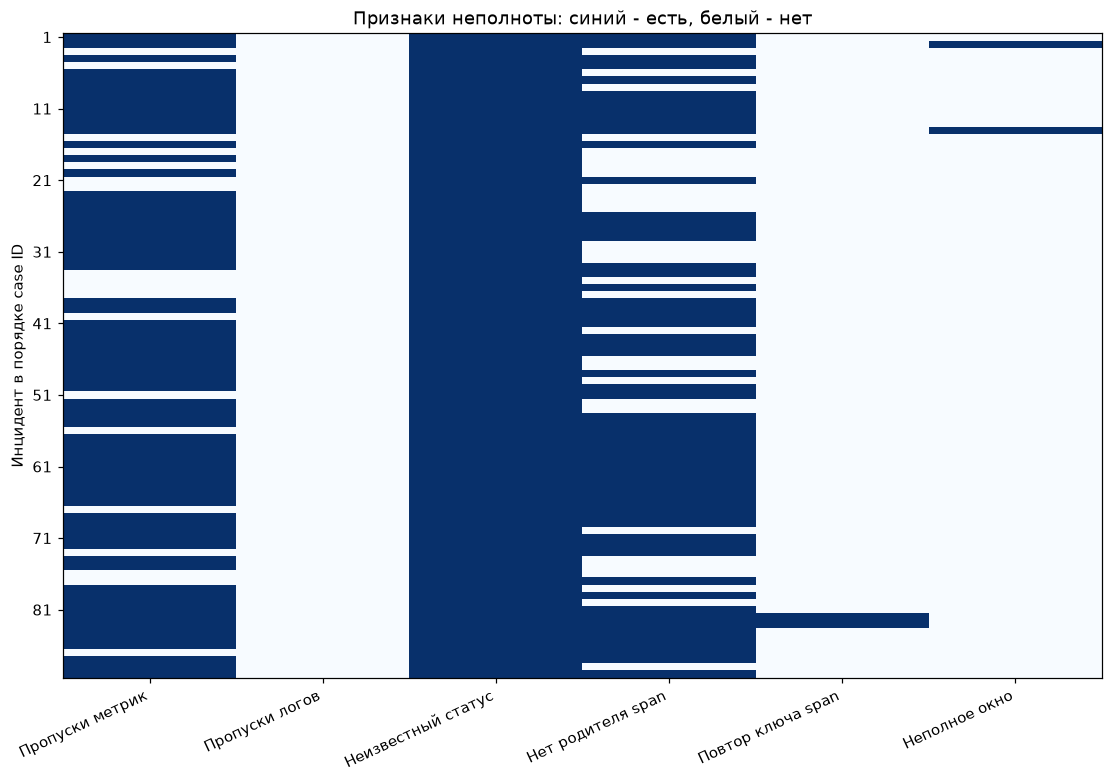

In [8]:
display(
    quality.groupby("source")[["rows", "missing_pct", "duplicate_pct"]]
    .agg(["min", "median", "max"])
    .round(2)
)
display(
    quality[~quality["full_window"]][
        ["case", "source", "before_minutes", "after_minutes"]
    ].round(2)
)

case_quality = quality.pivot(index="case", columns="source")
flags = pd.DataFrame(
    {
        "Пропуски метрик": case_quality["missing_values"]["metrics"] > 0,
        "Пропуски логов": case_quality["missing_pct"]["logs"] > 0,
        "Неизвестный статус": case_quality["unknown_status_pct"]["traces"] > 0,
        "Нет родителя span": case_quality["missing_parents"]["traces"] > 0,
        "Повтор ключа span": case_quality["duplicate_span_keys"]["traces"] > 0,
        "Неполное окно": ~case_quality["full_window"].all(axis=1),
    }
)
display(flags.sum().rename("затронуто инцидентов").to_frame())
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.imshow(flags, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(flags.columns)), flags.columns, rotation=25, ha="right")
ax.set_yticks(range(0, len(flags), 10), range(1, len(flags) + 1, 10))
ax.set(
    ylabel="Инцидент в порядке case ID",
    title="Признаки неполноты: синий - есть, белый - нет",
)
plt.show()

### Объём данных на инцидент

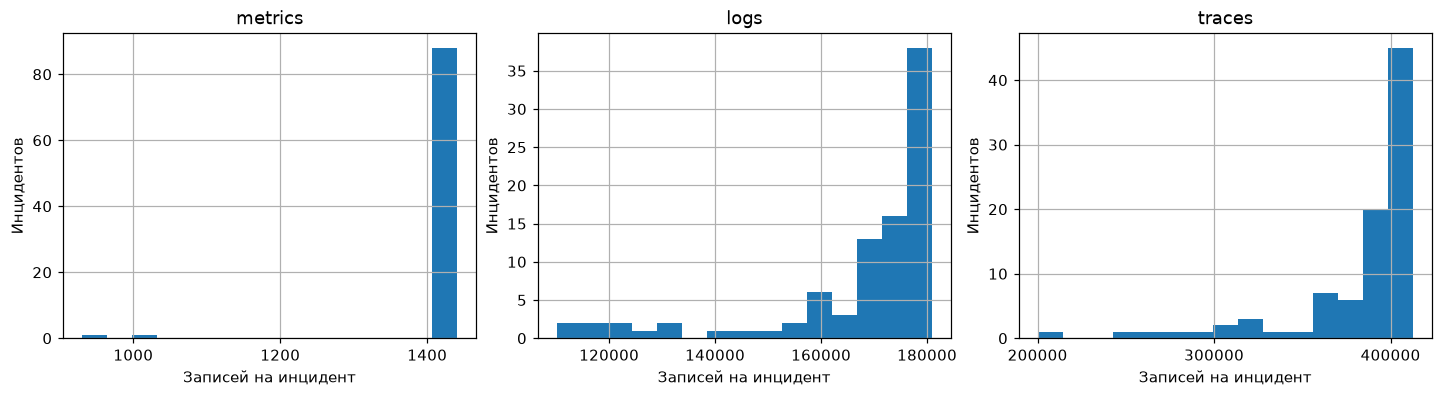

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for source, ax in zip(["metrics", "logs", "traces"], axes):
    quality.loc[quality["source"] == source, "rows"].hist(bins=15, ax=ax)
    ax.set(title=source, xlabel="Записей на инцидент", ylabel="Инцидентов")
    ax.locator_params(axis="x", nbins=4)
plt.show()

### Покрытие сервисов и инфраструктурных сущностей

Если сервиса нет в источнике, значит, о нём нет записей. `frontend-external` остаётся отдельной сущностью.

Префиксы метрик могут обозначать инфраструктуру, например `PassthroughCluster` или `istio-init`. Их нельзя автоматически включать в каталог бизнес-сервисов.

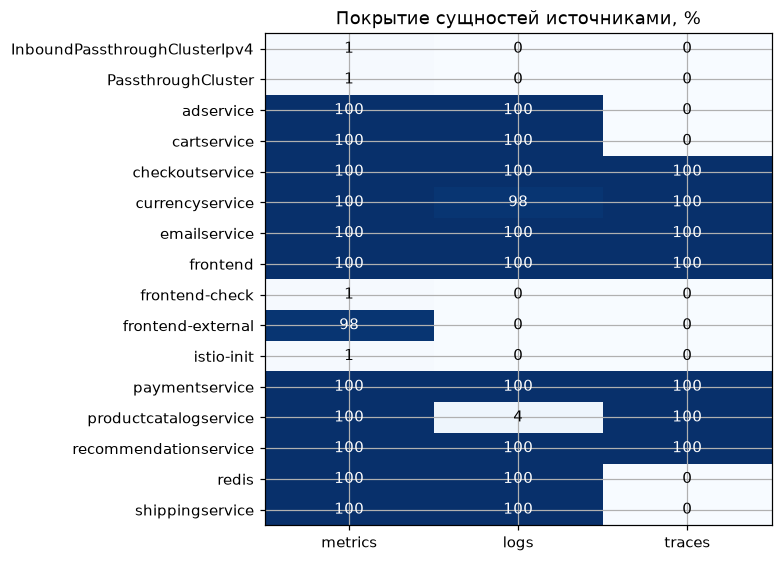

In [96]:
service_coverage = (
    pd.crosstab(presence["service"], presence["source"]) / len(cases) * 100
)
service_coverage = service_coverage[["metrics", "logs", "traces"]]
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.imshow(service_coverage, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(3), service_coverage.columns)
ax.set_yticks(range(len(service_coverage)), service_coverage.index)
ax.set_title("Покрытие сущностей источниками, %")
for i in range(len(service_coverage)):
    for j in range(3):
        value = service_coverage.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            color="white" if value > 50 else "black",
        )
plt.show()

## 4. Изменения до и после сигнала на development

Сравниваем равные окна `[-300, 0)` и `[0, 300)` секунд. Для каждого источника берём только случаи, у которых полная запись покрывает обе границы. Пропуски внутри окна не заполняем и показываем число доступных значений.

Для диагностических сравнений используем только development.

In [97]:
full_cases = quality[quality["full_window"]].groupby("source")["case"].agg(set)
dev_ids = set(dev_cases["case"])
for source in ["metrics", "logs", "traces"]:
    selected = dev_ids & full_cases[source]
    print(f"{source}: полных development-случаев {len(selected)} из {len(dev_ids)}")

metrics: полных development-случаев 53 из 54
logs: полных development-случаев 53 из 54
traces: полных development-случаев 53 из 54


### Метрики сервиса с внедрённым сбоем

Для EDA выбираем сервис по известной разметке.

Считаем отношение медиан «после / до» отдельно для каждого инцидента. Если медиана до сигнала нулевая, получаем пропуск.

In [98]:
metric_rows = []
for case in dev_cases.itertuples():
    if case.case not in full_cases["metrics"]:
        continue
    data = pd.read_parquet(DATA_DIR / case.case / "metrics.parquet")
    seconds = data["time"] - case.inject_time
    before = data[(seconds >= -300) & (seconds < 0)]
    after = data[(seconds >= 0) & (seconds < 300)]
    for metric in ["cpu", "mem", "latency-90"]:
        column = f"{case.root_cause_service}_{metric}"
        old_value, new_value = before[column].median(), after[column].median()
        metric_rows.append(
            {
                "case": case.case,
                "service": case.root_cause_service,
                "fault": case.fault,
                "metric": metric,
                "n_before": before[column].count(),
                "n_after": after[column].count(),
                "before": old_value,
                "after": new_value,
                "ratio": new_value / old_value if old_value != 0 else np.nan,
            }
        )
metric_changes = pd.DataFrame(metric_rows)
display(
    metric_changes.groupby(["fault", "metric"])["ratio"]
    .agg(["count", "median"])
    .round(2)
)

count  median
fault  metric                   
cpu    cpu             8    7.10
       latency-90      8    9.69
       mem             8    1.34
delay  cpu             9    1.08
       latency-90      9   47.08
...                  ...     ...
mem    latency-90      9   56.67
       mem             9    6.17
socket cpu             9    2.80
       latency-90      9    9.63
       mem             9    1.24

[18 rows x 2 columns]

Сравниваем распределения.

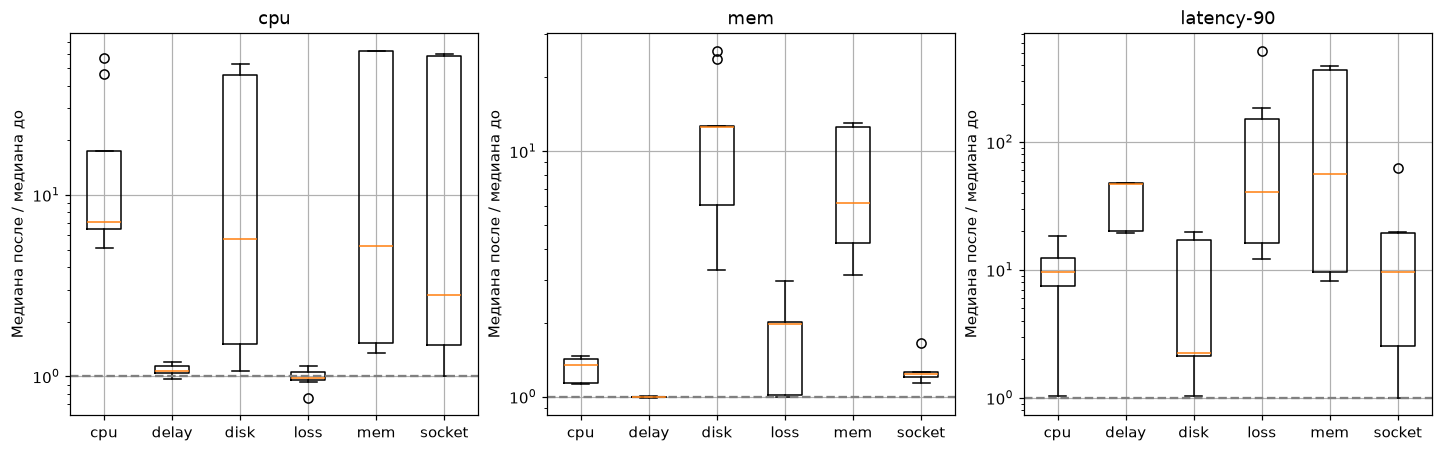

,case,service,fault,metric,n_before,n_after,before,after,ratio


In [99]:
fault_order = sorted(dev_cases["fault"].unique())
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for metric, ax in zip(["cpu", "mem", "latency-90"], axes):
    part = metric_changes[
        (metric_changes["metric"] == metric) & (metric_changes["ratio"] > 0)
    ]
    groups = [
        part.loc[part["fault"] == fault, "ratio"].dropna() for fault in fault_order
    ]
    ax.boxplot(groups, tick_labels=fault_order)
    ax.set_yscale("log")
    ax.axhline(1, color="gray", linestyle="--")
    ax.set(title=metric, ylabel="Медиана после / медиана до")
plt.show()
display(metric_changes[metric_changes["ratio"].isna() | (metric_changes["ratio"] <= 0)])

### Разброс повторов

Показываем медиану, минимум и максимум отношения внутри одной пары «сервис × сбой». После исключения неполных окон повторов может остаться меньше трёх. В разных fault-группах development.

In [101]:
repeat_spread = metric_changes.groupby(["service", "fault", "metric"])["ratio"].agg(
    ["count", "median", "min", "max"]
)
repeat_spread["range"] = repeat_spread["max"] - repeat_spread["min"]
display(repeat_spread.sort_values("range", ascending=False).head(10).round(2))

count  median     min     max   range
service               fault  metric                                           
recommendationservice loss   latency-90      3  184.34  152.65  517.96  365.30
productcatalogservice mem    latency-90      3   56.67   54.75  350.67  295.92
recommendationservice socket latency-90      3    9.63    1.00   62.81   61.81
emailservice          loss   latency-90      3   40.49   26.09   86.96   60.87
                      mem    latency-90      3  380.43  365.47  395.33   29.86
checkoutservice       disk   mem             3   23.67   12.73   25.68   12.96
                      cpu    cpu             2   51.66   46.56   56.77   10.21
productcatalogservice cpu    latency-90      3   18.39   10.44   18.42    7.98
checkoutservice       disk   cpu             3   50.25   45.93   52.65    6.72
recommendationservice socket cpu             3    2.80    1.00    6.91    5.90

### Логи: объём и текстовые признаки ошибок

Считаем сообщения и долю совпадений с регулярным выражением. Это эвристика без готовой разметки ошибок. Если совпадений нет, это не доказывает, что сбоя не было.

In [102]:
error_pattern = (
    r"(?i)\b(?:error|exception|failed|failure|fail|timeout|timed\s+out|panic|fatal)\b"
)
log_rows = []
for case in dev_cases.itertuples():
    if case.case not in full_cases["logs"]:
        continue
    data = pd.read_parquet(DATA_DIR / case.case / "logs.parquet")
    seconds = data["timestamp"] - case.inject_time
    before = data[(seconds >= -300) & (seconds < 0)]
    after = data[(seconds >= 0) & (seconds < 300)]
    log_rows.append(
        {
            "case": case.case,
            "fault": case.fault,
            "rows_before": len(before),
            "rows_after": len(after),
            "error_before_pct": 100
            * before["message"].str.contains(error_pattern, na=False).mean(),
            "error_after_pct": 100
            * after["message"].str.contains(error_pattern, na=False).mean(),
        }
    )
log_changes = pd.DataFrame(log_rows)
log_changes["volume_ratio"] = log_changes["rows_after"] / log_changes[
    "rows_before"
].replace(0, np.nan)
log_changes["error_delta_pp"] = (
    log_changes["error_after_pct"] - log_changes["error_before_pct"]
)
display(
    log_changes.groupby("fault")[["volume_ratio", "error_delta_pp"]]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

volume_ratio                    error_delta_pp                  
              count median   min   max          count median  min   max
fault                                                                  
cpu               8   1.00  0.97  1.02              8   0.00  0.0  0.00
delay             9   0.99  0.94  1.02              9   0.00  0.0  0.00
disk              9   0.99  0.81  1.01              9   0.00  0.0  0.00
loss              9   0.95  0.76  1.02              9   0.03  0.0  1.71
mem               9   0.88  0.63  1.03              9   0.02  0.0  0.21
socket            9   0.98  0.94  1.04              9   0.00  0.0  0.00

### Трассы: длительность одинаковых операций

Сравниваем одну и ту же пару «владелец span × операция» в каждом инциденте. Оставляем операции с минимум 30 корректными длительностями в обоих окнах.

In [103]:
operation_tables = []
for case in dev_cases.itertuples():
    if case.case not in full_cases["traces"]:
        continue
    data = pd.read_parquet(DATA_DIR / case.case / "traces.parquet")
    seconds = data["startTimeMillis"] / 1000 - case.inject_time
    data = data[(seconds >= -300) & (seconds < 300)].copy()
    data["period"] = np.where(
        data["startTimeMillis"] / 1000 < case.inject_time, "before", "after"
    )
    data["duration_ms"] = (data["duration"] / 1000).where(data["duration"] >= 0)
    grouped = data.groupby(["serviceName", "operationName", "period"])["duration_ms"]
    counts = grouped.count().unstack("period")
    p95 = grouped.quantile(0.95).unstack("period")
    changes = p95[counts[["before", "after"]].ge(30).all(axis=1)].copy()
    changes["n_before"], changes["n_after"] = counts["before"], counts["after"]
    changes["delta_ms"] = changes["after"] - changes["before"]
    changes["case"], changes["fault"] = case.case, case.fault
    operation_tables.append(changes.reset_index())
operation_changes = pd.concat(operation_tables, ignore_index=True)
display(operation_changes.nlargest(10, "delta_ms").round(2))

period,serviceName,operationName,after,before,n_before,n_after,delta_ms,case,fault
299,checkoutservice,hipstershop.CheckoutService/PlaceOrder,16938.07,607.24,140,93,16330.83,re2ob_checkoutservice_loss_1,loss
316,frontendservice,hipstershop.CheckoutService/PlaceOrder,16817.67,610.37,140,111,16207.3,re2ob_checkoutservice_loss_1,loss
373,checkoutservice,hipstershop.CheckoutService/PlaceOrder,16024.71,151.44,135,147,15873.27,re2ob_checkoutservice_loss_3,loss
390,frontendservice,hipstershop.CheckoutService/PlaceOrder,16027.92,154.86,135,147,15873.06,re2ob_checkoutservice_loss_3,loss
376,checkoutservice,hipstershop.PaymentService/Charge,14225.14,9.14,135,147,14215.99,re2ob_checkoutservice_loss_3,loss
1763,frontendservice,hipstershop.RecommendationService/ListRecommendations,6661.05,10.49,2665,2092,6650.57,re2ob_recommendationservice_loss_1,loss
1754,frontendservice,frontend,6319.17,760.77,3733,2913,5558.4,re2ob_recommendationservice_loss_1,loss
1422,frontendservice,frontend,5348.71,803.03,3809,2442,4545.68,re2ob_productcatalogservice_mem_1,mem
353,frontendservice,hipstershop.CheckoutService/PlaceOrder,4583.0,221.05,124,136,4361.96,re2ob_checkoutservice_loss_2,loss
306,checkoutservice,opentelemetry.proto.collector.trace.v1.TraceService/Export,4279.47,4.08,60,56,4275.39,re2ob_checkoutservice_loss_1,loss


Чтобы большой инцидент не получил больший вес, сначала берём медиану сдвигов p95 его операций. Затем показываем распределение этих медиан по типам сбоев. Такой показатель описывает типичную операцию случая и не заменяет end-to-end latency.

In [104]:
case_latency = (
    operation_changes.groupby(["case", "fault"])["delta_ms"].median().reset_index()
)
display(
    case_latency.groupby("fault")["delta_ms"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

,count,median,min,max
fault,,,,
cpu,8,0.01,-0.04,0.24
delay,9,0.0,-0.01,0.22
disk,9,0.22,0.07,0.77
loss,9,0.01,0.0,0.92
mem,9,1.6,0.12,5.1
socket,9,0.06,-0.0,0.25


## 5. Разбор одного случая

In [106]:
CASE_ID = dev_cases.iloc[0]["case"]
case = dev_cases.set_index("case").loc[CASE_ID]
folder = DATA_DIR / CASE_ID
metrics = pd.read_parquet(folder / "metrics.parquet")
logs = pd.read_parquet(folder / "logs.parquet")
traces = pd.read_parquet(folder / "traces.parquet")
inject_time = case["inject_time"]
print(CASE_ID)
display(quality[quality["case"] == CASE_ID].dropna(axis=1, how="all"))

re2ob_checkoutservice_cpu_1


,case,source,rows,missing_pct,duplicate_pct,invalid_time,before_minutes,...,message_length_p95,empty_messages,unknown_status_pct,duplicate_span_keys,missing_parents,missing_parent_pct,time_mismatch
0,re2ob_checkoutservice_cpu_1,metrics,1441,0.003803,0.000000,0,12.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,re2ob_checkoutservice_cpu_1,logs,171322,0.000000,66.140951,0,12.000000,...,109.0,0.0,NaN,NaN,NaN,NaN,NaN
180,re2ob_checkoutservice_cpu_1,traces,391997,1.408081,0.000000,0,11.998917,...,NaN,NaN,4.687281,0.0,7.0,0.001902,0.0


### Метрики выбранного случая

Показываем CPU и память сервиса с внедрённым сбоем. Единицы метрик не подтверждены, поэтому сохраняем исходную шкалу.

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,...,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,...,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,...,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,...,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,...,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,...,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


recommendationservice_cpu       1
redis_cpu                       1
recommendationservice_diskio    1
redis_diskio                    1
Name: пропуски, dtype: int64

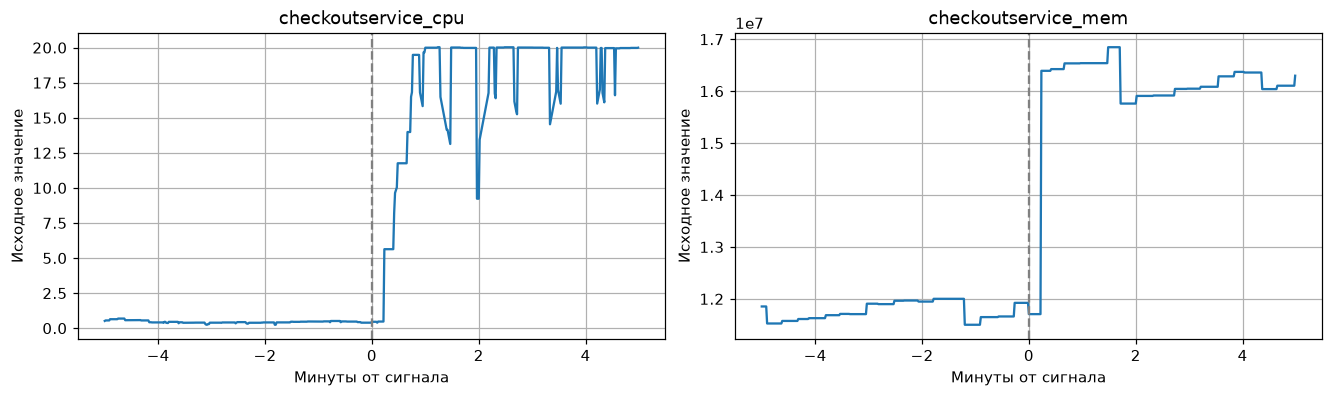

In [107]:
display(metrics.head())
display(metrics.isna().sum()[metrics.isna().any()].rename("пропуски"))
seconds = metrics["time"] - inject_time
window = (seconds >= -300) & (seconds < 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
for metric, ax in zip(["cpu", "mem"], axes):
    column = f"{case['root_cause_service']}_{metric}"
    ax.plot(seconds[window] / 60, metrics.loc[window, column])
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(title=column, xlabel="Минуты от сигнала", ylabel="Исходное значение")
plt.show()

### Логи выбранного случая

Повторяющиеся сообщения оставляем. Если в интервале нет записей, значит, в файле нет событий, но это не доказывает, что запросов не было.

,timestamp,container_name,message
0,1705353846,currencyservice,conversion request successful
1,1705353846,currencyservice,conversion request successful
2,1705353846,frontend,request started
3,1705353846,frontend,serving product page
4,1705353846,currencyservice,conversion request successful


,записей
message,
conversion request successful,39923
request started,18374
request complete,18373
Getting supported currencies...,14831
serving product page,8473
[GetQuote] received request,4457
[GetQuote] completed request,4457
view user cart,3788


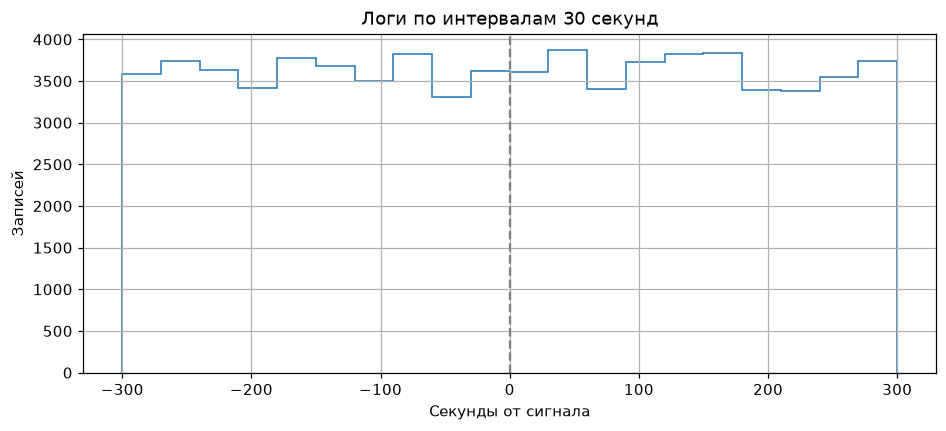

In [108]:
display(logs.head())
display(logs["message"].value_counts().head(8).to_frame("записей"))
seconds = logs["timestamp"] - inject_time
window = (seconds >= -300) & (seconds < 300)
bins = (seconds[window] // 30) * 30
volume = logs[window].groupby(bins).size().reindex(range(-300, 300, 30), fill_value=0)
fig, ax = plt.subplots()
ax.stairs(volume, range(-300, 301, 30))
ax.set_xlabel("Секунды от сигнала")
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Логи по интервалам 30 секунд", ylabel="Записей")
plt.show()

### Трассы выбранного случая

По [описанию RCAEval](https://github.com/phamquiluan/RCAEval/blob/main/RCAEval/convert/otlp.py#L6) статус 0 означает записанный OK, а пропуск остаётся неизвестным. Даже OK не исключает ресурсную деградацию. `serviceName` обозначает владельца span, в том числе клиентской операции.

In [109]:
display(traces.head())
display(traces.isna().sum()[traces.isna().any()].rename("пропуски"))
display(traces["statusCode"].value_counts(dropna=False).to_frame("span"))
display(
    operation_changes[operation_changes["case"] == CASE_ID]
    .nlargest(10, "delta_ms")
    .round(2)
)

,time,traceID,spanID,serviceName,methodName,operationName,parentSpanID,startTimeMillis,startTime,duration,statusCode
0,21:24,46d5d1e1fc25a09db4a81d4d105cee3d,de79080386c4c5c3,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,433c41ba31b519dd,1705353846065,1705353846065999,186,0
1,21:24,46d5d1e1fc25a09db4a81d4d105cee3d,433c41ba31b519dd,frontendservice,Convert,hipstershop.CurrencyService/Convert,6de46372468bc931,1705353846065,1705353846065431,4133,0
2,21:24,46d5d1e1fc25a09db4a81d4d105cee3d,28de2c1a557175ec,frontendservice,Convert,hipstershop.CurrencyService/Convert,6de46372468bc931,1705353846069,1705353846069657,3587,0
3,21:24,46d5d1e1fc25a09db4a81d4d105cee3d,a6ccc9fc0e441e5c,currencyservice,Convert,grpc.hipstershop.CurrencyService/Convert,28de2c1a557175ec,1705353846071,1705353846071000,134,0
4,21:24,26e74eeaa91cde16a44883aa36a33007,926d999ebf94ce86,frontendservice,<NA>,frontend,<NA>,1705353846073,1705353846073074,222894,<NA>


methodName      18374
parentSpanID    23968
statusCode      18374
Name: пропуски, dtype: int64

,span
statusCode,
0,373623
<NA>,18374


period,serviceName,operationName,after,before,n_before,n_after,delta_ms,case,fault
10,checkoutservice,opentelemetry.proto.collector.trace.v1.TraceService/Export,89.0,4.25,60,60,84.75,re2ob_checkoutservice_cpu_1,cpu
8,checkoutservice,hipstershop.ShippingService/GetQuote,29.53,4.82,145,155,24.71,re2ob_checkoutservice_cpu_1,cpu
21,frontendservice,hipstershop.CurrencyService/Convert,188.21,164.3,7790,7890,23.91,re2ob_checkoutservice_cpu_1,cpu
7,checkoutservice,hipstershop.ProductCatalogService/GetProduct,26.47,3.53,339,342,22.94,re2ob_checkoutservice_cpu_1,cpu
6,checkoutservice,hipstershop.PaymentService/Charge,28.62,8.71,145,155,19.91,re2ob_checkoutservice_cpu_1,cpu
2,checkoutservice,hipstershop.CartService/GetCart,23.91,5.78,145,156,18.13,re2ob_checkoutservice_cpu_1,cpu
9,checkoutservice,hipstershop.ShippingService/ShipOrder,22.06,5.0,145,155,17.06,re2ob_checkoutservice_cpu_1,cpu
1,checkoutservice,hipstershop.CartService/EmptyCart,20.98,5.75,145,155,15.23,re2ob_checkoutservice_cpu_1,cpu
27,frontendservice,opentelemetry.proto.collector.trace.v1.TraceService/Export,29.47,16.26,82,82,13.2,re2ob_checkoutservice_cpu_1,cpu
5,checkoutservice,hipstershop.EmailService/SendOrderConfirmation,16.64,4.74,145,155,11.9,re2ob_checkoutservice_cpu_1,cpu


## Выводы по сохранённому запуску

- **Окно доступно не всегда.** У двух инцидентов хотя бы один источник не покрывает пять минут после сигнала.
- **Качество источников различается.** Метрики идут с шагом 1 с, но содержат пропуски. Медианная доля совпадающих строк в логах: 66,7%; их нельзя автоматически удалять. В трассах неизвестные статусы есть во всех случаях, ненайденные родители в 60, повторные ключи span в двух.
- **Рост показателя не определяет тип сбоя.** На development CPU растёт также при `mem` и `disk`; при `disk` медиана отношения памяти после/до составляет около 12,5. Нужны несколько согласованных признаков, а не правило по одному показателю. Состав сервисов в fault-группах различается.
- **Логи часто не дают явного текста ошибки.** Для `cpu`, `delay`, `disk` и `socket` выбранная эвристика не показывает роста доли таких сообщений. Это ограничение поиска, а не доказательство отсутствия сбоя.
- **Источники покрывают разные сущности.** Например, `productcatalogservice` есть в метриках и трассах всех случаев, но встречается в логах только четырёх. Агент должен отличать отсутствие наблюдений от нормальной работы.